# 01 - Data audit, cleaning & regularised feature pipeline
**Synthetic educational data** - nothing here proves real-world performance (rule 09).

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "smartcity" / "pipeline"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import smartcity_pipeline as sp
pd.set_option("display.width", 160)

## 1. Load + validate
Checks: duplicate IDs, orphan `location_id`s, missing values, censored durations.

In [2]:
loc, inc, com = sp.load_raw()
loc, inc, com, q = sp.clean(loc, inc, com)
q

{'rows': {'locations': 1000, 'incidents': 10000, 'complaints': 8000},
 'duplicate_ids': {'incidents': 0, 'complaints': 0},
 'orphan_location_ids': 0,
 'missing_values': 0,
 'unresolved_with_hours_censored': 2874,
 'complaints_open': 3438,
 'synthetic': True}

**Cleaning decisions**
- `resolved == 0` rows still carry `resolution_hours` -> *time open so far* (right-censored). They are excluded from fix-time medians and counted as backlog.
- Durations are winsorised at the 1st/99th percentile so outliers cannot dominate rankings.
- Categorical severity/priority mapped to ordinal weights (Low 1, Medium 2, High 4, Critical 8).

           count  mean   std  min   25%   50%   75%    max
severity                                                  
Critical   470.0  31.2  21.6  1.3  15.1  26.3  42.8  130.6
High      1985.0  32.7  22.9  1.0  16.6  27.4  43.5  184.7
Low       3819.0  32.6  23.1  1.0  15.8  27.2  43.5  191.9
Medium    3726.0  31.7  21.8  1.0  15.5  26.9  43.1  141.8


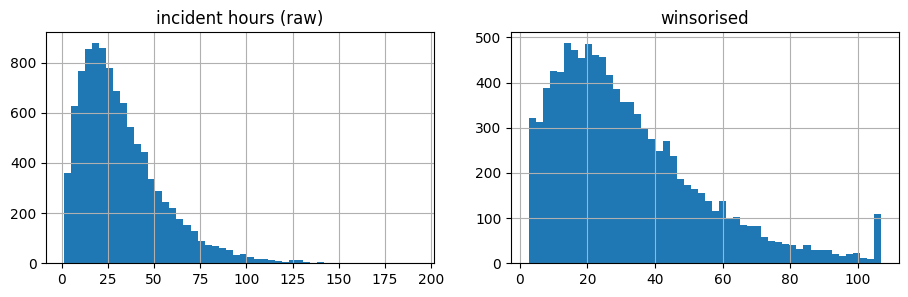

In [3]:
print(inc.groupby('severity').resolution_hours.describe().round(1))
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
inc.resolution_hours.hist(bins=50, ax=ax[0]); ax[0].set_title('incident hours (raw)')
inc.resolution_hours_w.hist(bins=50, ax=ax[1]); ax[1].set_title('winsorised'); plt.show()

## 2. Is there signal? (honest EDA)
If incident counts per location look like pure Poisson noise, rankings are mostly noise and the product must show that uncertainty.

In [4]:
n = inc.groupby('location_id').size().reindex(loc.location_id, fill_value=0)
print('mean %.2f  std %.2f  | Poisson std would be %.2f' % (n.mean(), n.std(), n.mean()**.5))
from scipy.stats import kruskal
l2 = loc.assign(n=n.values)
for c in ['road_condition','road_type','pedestrian_activity','zone','near_school','near_hospital']:
    print(f'{c:22s} Kruskal p = {kruskal(*[g.n.values for _, g in l2.groupby(c)]).pvalue:.3f}')

mean 10.00  std 3.25  | Poisson std would be 3.16
road_condition         Kruskal p = 0.898
road_type              Kruskal p = 0.562
pedestrian_activity    Kruskal p = 0.832
zone                   Kruskal p = 0.778
near_school            Kruskal p = 0.529
near_hospital          Kruskal p = 0.968


Counts are ~Poisson(10) and unrelated to context attributes. **Consequence:** we (a) shrink sparse locations toward their zone mean, (b) bootstrap rank intervals, (c) label confidence, and (d) never claim forecasting skill.

## 3. Regularisation set-up
1. **Empirical-Bayes shrinkage**: `load = (n*raw + k*zone_mean)/(n+k)`, k=3.
2. **Recency decay** half-life 120 days.
3. **Percentile normalisation** of each component (robust to scale/outliers).
4. **Poisson bootstrap** (200x) for rank stability.
5. L2 / L1+L2 regularisation in the models of notebook 02.

In [5]:
asof = pd.Timestamp('2026-01-01')
f = sp.location_features(loc, inc, com, asof)
s = sp.score(f)
d = f.merge(s, on='location_id')
print('raw vs shrunk load spread:', f.sev_load_raw.std().round(2), '->', f.sev_load.std().round(2))
d.sort_values('score', ascending=False)[['location_id','zone','n_inc','n_com','score']].head(10)

raw vs shrunk load spread: 4.43 -> 3.39


,location_id,zone,n_inc,n_com,score
641,L0642,ZONE_02,11.0,14.0,97.4650
299,L0300,ZONE_04,10.0,11.0,91.9200
139,L0140,ZONE_02,14.0,9.0,91.7350
728,L0729,ZONE_12,17.0,9.0,91.5000
493,L0494,ZONE_14,14.0,14.0,90.1850
180,L0181,ZONE_06,14.0,10.0,90.1850
492,L0493,ZONE_18,16.0,9.0,89.7750
555,L0556,ZONE_02,14.0,9.0,89.4150
218,L0219,ZONE_10,16.0,10.0,88.3150
459,L0460,ZONE_16,14.0,10.0,87.8325


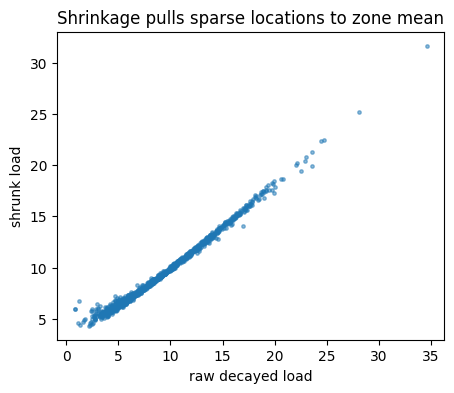

In [6]:
plt.figure(figsize=(5,4)); plt.scatter(f.sev_load_raw, f.sev_load, s=6, alpha=.5); plt.xlabel('raw decayed load'); plt.ylabel('shrunk load'); plt.title('Shrinkage pulls sparse locations to zone mean'); plt.show()

## 4. Leakage guard
`location_features(..., asof)` only uses events strictly before `asof`; targets in notebook 02 come strictly after the cutoff.